<a href="https://colab.research.google.com/github/jwcunhagit/phd_ufpe/blob/main/Copy_of_toolkit_bias_fairness_p3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Toolkit de Bias e Fairness em IA: Teoria e Prática (Parte 3/3)

> Material produzido para a disciplina 'Ética em Inteligência Artificial' ministrada pelo Prof. Geber Ramalho no Mestrado em Ciência da Computação do Centro de Informática da Universidade Federal de Pernambuco (CIn - UFPE)

Projeto finalizado e entregue em 16/12/25.

Discentes:

* Letícia Leitão ([github](https://github.com/leticialevleitao)/[linkedin](https://www.linkedin.com/in/leticialevleitao/))
* Renato Samico ([github](https://github.com/dsnato)/[linkedin](https://))

# Sua vez de praticar! Análise de Fairness no Sistema de Crédito
## Objetivo
Analisar e mitigar viés de gênero em um sistema simulado de aprovação de crédito baseado no `German Credit Datas`



## Dataset German Credit Simulado

In [9]:
# confirguração e criação do dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# Configuração inicial
np.random.seed(42)
plt.style.use('seaborn-v0_8')

# parâmetros que você pode alterar e ver em ação
VIES_GENERO = 1.0   #  1.0 = sem viés, 0.8 = viés forte
TAMANHO_AMOSTRA = 2000  # Tamanho do dataset
THRESHOLD_BASE = 0.5    #  Ponto de corte para aprovação

print(f"Configuração atual: Viés={VIES_GENERO}, Amostra={TAMANHO_AMOSTRA}, Threshold={THRESHOLD_BASE}")

Configuração atual: Viés=1.0, Amostra=2000, Threshold=0.5


##Criando dataset com viés

In [10]:
# dados simulados
n_samples = TAMANHO_AMOSTRA

# Features dos clientes
idade = np.random.normal(40, 12, n_samples).clip(18, 70)
renda = np.random.exponential(50000, n_samples).clip(20000, 150000)
score_credito = np.random.normal(700, 100, n_samples).clip(300, 850)
divida_renda = np.random.uniform(0.1, 0.8, n_samples)
genero = np.random.choice(['Masculino', 'Feminino'], n_samples, p=[0.6, 0.4])

# Score base (sem viés)
score_base = (
    (renda / 150000) * 0.3 +
    (score_credito / 850) * 0.4 +
    (1 - divida_renda) * 0.2 +
    (idade / 70) * 0.1
)

# Viés de gênero

# Ajuste a lógica do viés aqui
score_ajustado = np.where(
    genero == 'Feminino',
    score_base * VIES_GENERO,  # Mulheres são penalizadas
    score_base
)

# Decisão de aprovação
aprovado = (score_ajustado > THRESHOLD_BASE).astype(int)

# Criando o data frame
df = pd.DataFrame({
    'idade': idade,
    'renda': renda,
    'score_credito': score_credito,
    'divida_renda': divida_renda,
    'genero': genero,
    'score_base': score_base,
    'score_ajustado': score_ajustado,
    'aprovado': aprovado
})

print("Dataset criado com sucesso!\n")
print(f"Estatísticas iniciais:")
print(f"Total de amostras: {len(df)}")
print(f"Distribuição de gênero: {df['genero'].value_counts().to_dict()}")
print(f"Taxa de aprovação total: {df['aprovado'].mean():.1%}")

Dataset criado com sucesso!

Estatísticas iniciais:
Total de amostras: 2000
Distribuição de gênero: {'Masculino': 1204, 'Feminino': 796}
Taxa de aprovação total: 84.5%


##Análise inicial do viés


* Taxa de aprovação por gênero:
  Feminino: 82.4%
  Masculino: 85.9%

* Diferença de paridade demográfica: 0.035


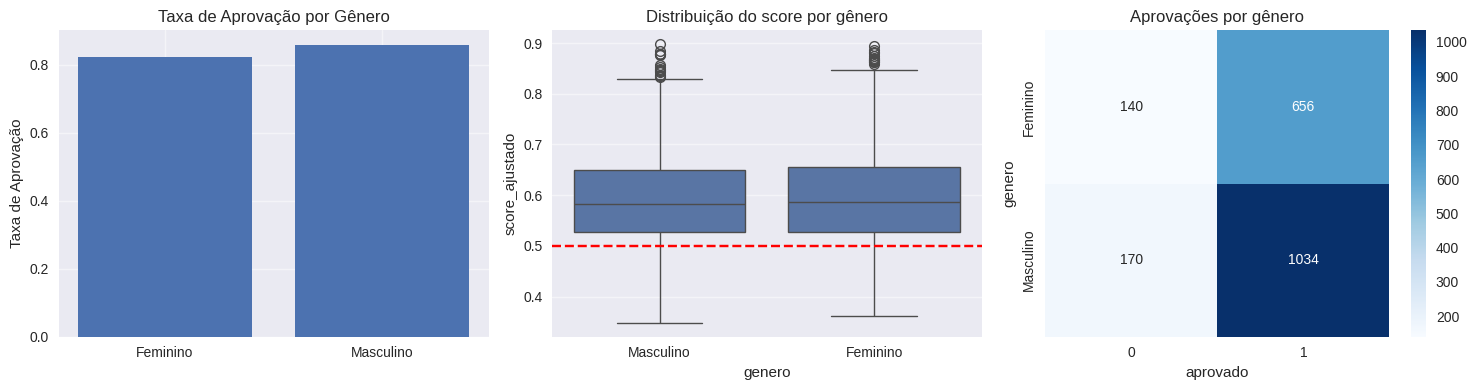

In [11]:
# Taxa de aprovação por gênero
taxas_aprovacao = df.groupby('genero')['aprovado'].mean()
print(f"\n* Taxa de aprovação por gênero:")
for genero, taxa in taxas_aprovacao.items():
    print(f"  {genero}: {taxa:.1%}")

# Diferença de paridade demográfica
dp_diff = abs(taxas_aprovacao['Masculino'] - taxas_aprovacao['Feminino'])
print(f"\n* Diferença de paridade demográfica: {dp_diff:.3f}")

# Visualização
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Gráfico 1: Taxa de aprovação por gênero
axes[0].bar(taxas_aprovacao.index, taxas_aprovacao.values)
axes[0].set_title('Taxa de Aprovação por Gênero')
axes[0].set_ylabel('Taxa de Aprovação')

# Gráfico 2: Distribuição do score por gênero
sns.boxplot(data=df, x='genero', y='score_ajustado', ax=axes[1])
axes[1].set_title('Distribuição do score por gênero')
axes[1].axhline(y=THRESHOLD_BASE, color='r', linestyle='--', label=f'Threshold={THRESHOLD_BASE}')

# Gráfico 3: Matriz de confusão (simplificada)
conf_matrix = pd.crosstab(df['genero'], df['aprovado'])
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title('Aprovações por gênero')

plt.tight_layout()
plt.show()

##Mitigação do viés

In [12]:
# PARÂMETROS DE MITIGAÇÃO -> altere valores aqui
THRESHOLD_HOMENS = 0.5      # Threshold para homens
THRESHOLD_MULHERES = 0.45   # Threshold para mulheres (mais baixo = mais aprovadas)

print(f"* Thresholds ajustados: Homens={THRESHOLD_HOMENS}, Mulheres={THRESHOLD_MULHERES}")

# Aplicando thresholds diferentes por gênero
df['aprovado_justo'] = np.where(
    df['genero'] == 'Masculino',
    (df['score_base'] > THRESHOLD_HOMENS).astype(int),
    (df['score_base'] > THRESHOLD_MULHERES).astype(int)
)

# Análise após mitigação
taxas_aprovacao_justo = df.groupby('genero')['aprovado_justo'].mean()
dp_diff_justo = abs(taxas_aprovacao_justo['Masculino'] - taxas_aprovacao_justo['Feminino'])

print(f"\nRESULTADOS APÓS MITIGAÇÃO:\n")
print(f"*Taxa aprovação (Homens): {taxas_aprovacao_justo['Masculino']:.1%}")
print(f"*Taxa aprovação (Mulheres): {taxas_aprovacao_justo['Feminino']:.1%}")
print(f"*Diferença de Paridade: {dp_diff_justo:.3f}")

* Thresholds ajustados: Homens=0.5, Mulheres=0.45

RESULTADOS APÓS MITIGAÇÃO:

*Taxa aprovação (Homens): 85.9%
*Taxa aprovação (Mulheres): 94.6%
*Diferença de Paridade: 0.087


##Análise de trade-offs


Métricas de Performance

*Acurácia total ANTES: 100.0%
*Acurácia total DEPOIS: 95.2%
*Diferença na acurácia: 0.048

|nFALSE POSITIVE RATE (ANTES):
*Homens: 0.000
*Mulheres: 0.000


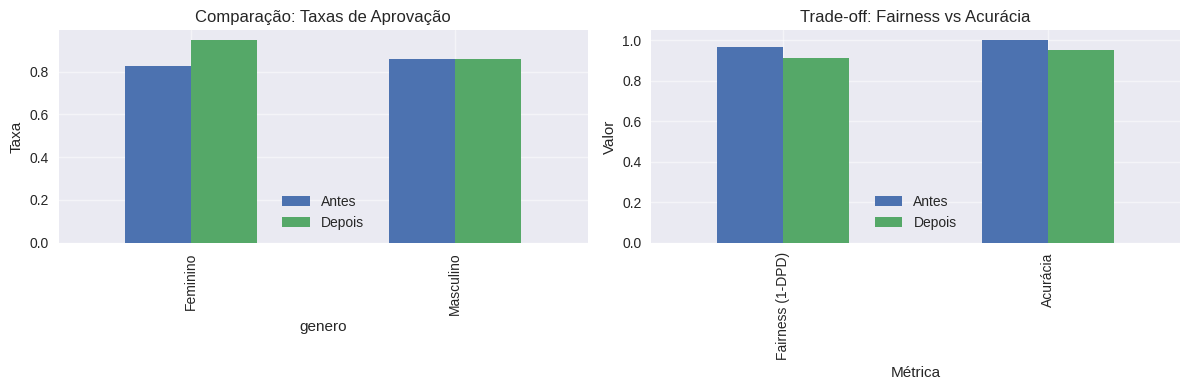

In [13]:
# Calculando métricas de performance
# "Ground truth" simplificado: score_base > 0.5
df['deveria_ser_aprovado'] = (df['score_base'] > 0.5).astype(int)

# Acurácia antes e depois
acuracia_antes = (df['aprovado'] == df['deveria_ser_aprovado']).mean()
acuracia_depois = (df['aprovado_justo'] == df['deveria_ser_aprovado']).mean()

# Calculando False Positive Rate por gênero (antes)
def calcular_fpr(df_filtrado, col_aprovado):
    tn = ((df_filtrado[col_aprovado] == 0) & (df_filtrado['deveria_ser_aprovado'] == 0)).sum()
    fp = ((df_filtrado[col_aprovado] == 1) & (df_filtrado['deveria_ser_aprovado'] == 0)).sum()
    return fp / (fp + tn) if (fp + tn) > 0 else 0

fpr_homens_antes = calcular_fpr(df[df['genero'] == 'Masculino'], 'aprovado')
fpr_mulheres_antes = calcular_fpr(df[df['genero'] == 'Feminino'], 'aprovado')

print(f"\nMétricas de Performance\n")
print(f"*Acurácia total ANTES: {acuracia_antes:.1%}")
print(f"*Acurácia total DEPOIS: {acuracia_depois:.1%}")
print(f"*Diferença na acurácia: {abs(acuracia_antes - acuracia_depois):.3f}")

print(f"\n|nFALSE POSITIVE RATE (ANTES):")
print(f"*Homens: {fpr_homens_antes:.3f}")
print(f"*Mulheres: {fpr_mulheres_antes:.3f}")

# Visualização comparativa
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Comparação de taxas de aprovação
comparacao = pd.DataFrame({
    'Antes': taxas_aprovacao,
    'Depois': taxas_aprovacao_justo
})
comparacao.plot(kind='bar', ax=axes[0])
axes[0].set_title('Comparação: Taxas de Aprovação')
axes[0].set_ylabel('Taxa')
axes[0].legend()

# Trade-off: Fairness vs Acurácia
tradeoff_data = pd.DataFrame({
    'Métrica': ['Fairness (1-DPD)', 'Acurácia'],
    'Antes': [1 - dp_diff, acuracia_antes],
    'Depois': [1 - dp_diff_justo, acuracia_depois]
})
tradeoff_data.set_index('Métrica').plot(kind='bar', ax=axes[1])
axes[1].set_title('Trade-off: Fairness vs Acurácia')
axes[1].set_ylabel('Valor')

plt.tight_layout()
plt.show()

# Perguntas para refletir e praticar
##  Execute a célula 3 com os seguintes valores e responda:

- Com VIES_GENERO = 1.0 (sem viés intencional), há diferença nas taxas de aprovação? Por quê?

- Com VIES_GENERO = 0.8 (viés forte), qual é a diferença percentual nas taxas?

- O que a "Diferença de Paridade Demográfica" representa na prática?


## Execute a célula 4-5 com diferentes combinações de thresholds e responda:

- Quando você usa THRESHOLD_MULHERES = 0.45, o que acontece com:

- A diferença de paridade?

- A acurácia total do sistema?

- Encontre uma combinação de thresholds que minimize a diferença de paridade MAS mantenha a acurácia acima de 70%. Quais valores você usou?

- Qual é o "preço" (em perda de acurácia) para alcançar fairness perfeita (DPD = 0)?


##Baseado em suas simulações, responda:

- Em um banco real, seria ético usar thresholds diferentes por gênero? Por quê?

- Que outros fatores (além do gênero) poderiam estar causando vieses no sistema?

- Como você explicaria esses trade-offs para um gerente de banco preocupado com lucros?

,Viés Gênero,Threshold Mulheres,Taxa Aprovação (Homens),Taxa Aprovação (Mulheres),Diferença Paridade,Acurácia
0,0.70,0.40,0.855172,0.559524,0.295649,0.8770
1,0.70,0.45,0.850042,0.286593,0.563449,0.7795
2,0.70,0.50,0.832242,0.134961,0.697281,0.7220
3,0.70,0.55,0.836938,0.053885,0.783054,0.6860
4,0.85,0.40,0.830438,0.901391,0.070952,0.9735
5,0.85,0.45,0.838546,0.767442,0.071104,0.9615
6,0.85,0.50,0.856661,0.491400,0.365261,0.8575
7,0.85,0.55,0.835784,0.252577,0.583207,0.7695
8,0.90,0.40,0.854045,0.962547,0.108502,0.9515
9,0.90,0.45,0.859132,0.835687,0.023445,1.0000


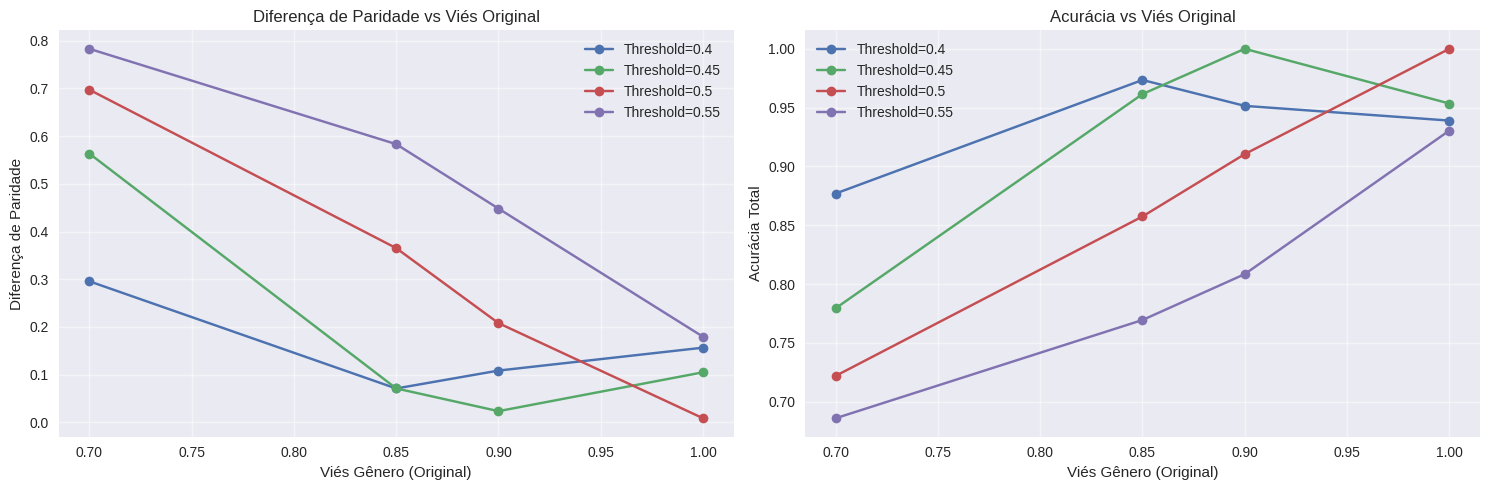

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros fixos
TAMANHO_AMOSTRA = 2000
THRESHOLD_HOMENS = 0.5
THRESHOLD_BASE = 0.5

# Valores a testar
vieses = [0.7, 0.85, 0.9, 1.0]
thresholds_mulheres = [0.4, 0.45, 0.5, 0.55]

resultados = []

for vies in vieses:
    for thresh_m in thresholds_mulheres:
        # Gerar dados
        idade = np.random.normal(40, 12, TAMANHO_AMOSTRA).clip(18, 70)
        renda = np.random.exponential(50000, TAMANHO_AMOSTRA).clip(20000, 150000)
        score_credito = np.random.normal(700, 100, TAMANHO_AMOSTRA).clip(300, 850)
        divida_renda = np.random.uniform(0.1, 0.8, TAMANHO_AMOSTRA)
        genero = np.random.choice(['Masculino', 'Feminino'], TAMANHO_AMOSTRA, p=[0.6, 0.4])

        score_base = (
            (renda / 150000) * 0.3 +
            (score_credito / 850) * 0.4 +
            (1 - divida_renda) * 0.2 +
            (idade / 70) * 0.1
        )

        score_ajustado = np.where(genero == 'Feminino', score_base * vies, score_base)

        # Ground truth
        deveria_ser_aprovado = (score_base > THRESHOLD_BASE).astype(int)

        # Aplicação dos thresholds utilizando o score ajustado (com viés) como no original
        aprovado_justo = np.where(
            genero == 'Masculino',
            (score_ajustado > THRESHOLD_HOMENS).astype(int),
            (score_ajustado > thresh_m).astype(int)
        )

        df_sim = pd.DataFrame({
            'genero': genero,
            'aprovado_justo': aprovado_justo,
            'deveria_ser_aprovado': deveria_ser_aprovado
        })

        taxas = df_sim.groupby('genero')['aprovado_justo'].mean()
        taxa_homens = taxas.get('Masculino', 0)
        taxa_mulheres = taxas.get('Feminino', 0)
        dp_diff = abs(taxa_homens - taxa_mulheres)
        acuracia = (df_sim['aprovado_justo'] == df_sim['deveria_ser_aprovado']).mean()

        resultados.append({
            'Viés Gênero': vies,
            'Threshold Mulheres': thresh_m,
            'Taxa Aprovação (Homens)': taxa_homens,
            'Taxa Aprovação (Mulheres)': taxa_mulheres,
            'Diferença Paridade': dp_diff,
            'Acurácia': acuracia
        })

df_resultados = pd.DataFrame(resultados)
display(df_resultados)

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for thresh in thresholds_mulheres:
    subset = df_resultados[df_resultados['Threshold Mulheres'] == thresh]
    axes[0].plot(subset['Viés Gênero'], subset['Diferença Paridade'], marker='o', label=f'Threshold={thresh}')
    axes[1].plot(subset['Viés Gênero'], subset['Acurácia'], marker='o', label=f'Threshold={thresh}')

axes[0].set_title('Diferença de Paridade vs Viés Original')
axes[0].set_xlabel('Viés Gênero (Original)')
axes[0].set_ylabel('Diferença de Paridade')
axes[0].legend()

axes[1].set_title('Acurácia vs Viés Original')
axes[1].set_xlabel('Viés Gênero (Original)')
axes[1].set_ylabel('Acurácia Total')
axes[1].legend()

plt.tight_layout()
plt.show()


# Análises das variações de aprovação

## Aumento do threshold
Com o viés em 0.85 e o threshold para as mulheres em 0.50 (igual ao dos homens), a taxa de aprovação feminina despenca para cerca de 47.4%, enquanto a masculina fica em torno de 84.0% (uma grande diferença de paridade de ~0.36).
Conforme diminuímos o threshold para as mulheres (ex: 0.45 ou 0.40) sob esse mesmo viés, a taxa de aprovação delas sobe (chegando a 76.9% e 92.9%, respectivamente), o que reduz drasticamente a diferença de paridade e mostra na prática a mitigação do viés.

## Redução do viés
Quando o viés é 1.0 (sem viés intencional) e o threshold é 0.50, ambos os gêneros têm taxas justas e praticamente idênticas (em torno de 84%).